# Pivot index and Vendi score: does specialization predict acceptance?

**Question.** When a PI submits a paper that departs from their own earlier work, is it less likely to be accepted?

**Team decisions used here**
1. Only papers from 2021 on. Earlier papers have no OpenReview ids, so namesakes get merged (one name such as "Yang Liu" maps to 31 profiles in 2021+). Every author, the PI included, is identified by their OpenReview id.
2. A resubmitted paper is kept once: the accepted version if there is one, otherwise the latest. As a check we also drop every paper in a chain (~450 chains in total).
3. The PI is the last author. A PI needs at least 5 papers in earlier years for their paper to enter the analysis.
4. Withdrawn and desk-rejected papers have no decision, so they are left out of the acceptance models. They do have reviewer scores, so they stay in the score models.

**Plan.** Data and measures first, then the raw patterns, then models from the simplest up.
The **main model is M2**: a linear probability model with one dummy per PI and per year, plus history length and team size.
The measures are computed in `scripts/specialization.py`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from statsmodels.discrete.conditional_models import ConditionalLogit

from scripts import specialization as sp

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Colours: first three categorical slots of a colour-blind-checked palette
BLUE, ORANGE, AQUA = "#257de0", "#f47230", "#00b894"
TEXT, MUTED, GRID = "#191919", "#666666", "#e5e5e5"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "font.size": 10,
    "text.color": TEXT,
    "axes.labelcolor": TEXT,
    "axes.edgecolor": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "lines.linewidth": 2,
})

## 1. Data

In [2]:
papers, embeddings = sp.load_master("../embeddings/master.parquet", min_year=2021)

print(f"Papers from 2021 on: {len(papers):,}")
papers["decision_group"].value_counts()

Papers from 2021 on: 30,433


decision_group
reject           13917
accept            9490
withdrawn         6860
desk_rejected      166
Name: count, dtype: int64

## 2. Resubmissions

Two papers are versions of the same submission when they share an author id, come from different years and have a cosine similarity of at least 0.90.

In [3]:
chain = sp.find_resubmission_chains(papers, embeddings, similarity_threshold=0.90)
n_chains = (chain.value_counts() > 1).sum()

# rule: keep last resubmission that was accepted or rejected
drop_team_rule = sp.resubmissions_to_drop(papers, chain, rule="accepted_or_latest")

# rule: drop all the chains
drop_all_chains = sp.resubmissions_to_drop(papers, chain, rule="drop_all")

print(f"Chains of resubmissions: {n_chains}")
print(f"Papers left out with the team rule: {len(drop_team_rule)}")
print(f"Papers left out when dropping whole chains: {len(drop_all_chains)}")

Chains of resubmissions: 433
Papers left out with the team rule: 449
Papers left out when dropping whole chains: 882


## 3. Measures

For a paper $j$ by PI $a$ in year $t$, the history $H(a,t)$ holds all of $a$'s papers (any author position) from years before $t$. With unit-length embeddings $e$:

| Measure | Definition | Reads as |
|---|---|---|
| `pivot index` | $1 - \cos(e_j, \bar e_{H})$, mean over **all** prior papers | distance from the PI's average past paper (main measure) |
| `pivot_recent` | same, past papers weighted by $2^{-\text{age}/2}$ | distance from the PI's *recent* agenda (section 8, on its own) |
| `vendi` | Vendi score of 5 past papers, averaged over 20 random draws | number of distinct directions in the PI's past work (1 to 5) |

The Vendi score is the exponential of the entropy of the eigenvalues of the $5 \times 5$ cosine-similarity matrix divided by 5. Fixing the number of papers at 5 keeps PIs with long and short histories comparable.

In [4]:
measures_team_rule = sp.compute_pi_measures(sp.build_author_papers(papers, drop_team_rule), embeddings)
measures_all_chains = sp.compute_pi_measures(sp.build_author_papers(papers, drop_all_chains), embeddings)

# pi_id is an OpenReview id (sometimes an e-mail address), so we do not print it
measures_team_rule.drop(columns="pi_id").describe().round(3)

,paper_idx,year,n_prior,career_years,pivot,pivot_recent,vendi
count,29984.000,29984.000,29984.000,29984.000,18205.000,18205.000,8713.000
mean,20935.373,2023.712,4.662,1.446,0.447,0.446,3.538
std,8800.444,1.339,8.708,1.441,0.141,0.142,0.341
min,5637.000,2021.000,0.000,0.000,0.093,0.088,1.887
25%,13306.750,2023.000,0.000,0.000,0.343,0.341,3.329
50%,21001.500,2024.000,1.000,1.000,0.435,0.433,3.577
75%,28570.250,2025.000,6.000,3.000,0.542,0.543,3.770
max,36069.000,2025.000,89.000,4.000,1.019,1.019,4.385


## 4. Analysis sample

We keep PI papers with at least 5 prior papers. Each measure is standardised on the decided papers, so every coefficient reads as **the change in the outcome for a one-standard-deviation increase in the measure**. This is simply z-standardizing our measure.

In [5]:
MEASURES = ["pivot", "pivot_recent", "vendi"]
MIN_PRIOR = 5


def make_sample(measures: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    # Returns (scored, decided): papers with a reviewer score, and accepted/rejected papers
    outcomes = papers[["decision_group", "accepted", "mean_score", "n_authors"]]
    sample = measures.merge(outcomes, left_on="paper_idx", right_index=True)
    sample = sample[sample["n_prior"] >= MIN_PRIOR].copy()

    sample["accepted"] = sample["accepted"].astype(int)
    sample["log_n_prior"] = np.log(sample["n_prior"])
    sample["pi_year"] = sample["pi_id"] + "_" + sample["year"].astype(str)

    decided = sample[sample["decision_group"].isin(["accept", "reject"])].copy()
    decided["pi_papers"] = decided.groupby("pi_id")["pi_id"].transform("size")    # PI's decided papers

    for column in MEASURES:
        mean, std = decided[column].mean(), decided[column].std()
        decided[column + "_z"] = (decided[column] - mean) / std
        sample[column + "_z"] = (sample[column] - mean) / std

    scored = sample.dropna(subset=["mean_score"]).copy()
    return scored, decided


scored, decided = make_sample(measures_team_rule)
scored_all_chains, decided_all_chains = make_sample(measures_all_chains)

print(f"Decided papers: {len(decided):,} from {decided['pi_id'].nunique():,} PIs, {decided['accepted'].mean():.1%} accepted")
print(f"Scored papers (withdrawn included): {len(scored):,}")
decided.groupby("year").size().rename("decided papers")

Decided papers: 6,920 from 1,553 PIs, 48.8% accepted
Scored papers (withdrawn included): 8,651


year
2022     377
2023     940
2024    1974
2025    3629
Name: decided papers, dtype: int64

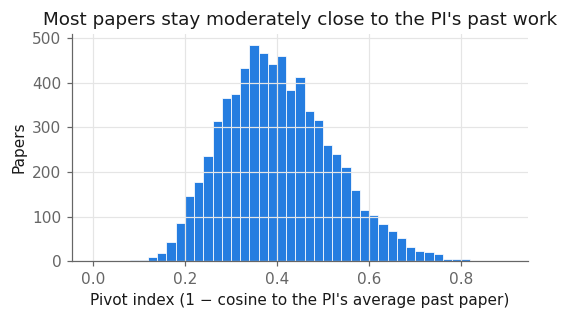

,pivot,pivot_recent,vendi
count,6920.000,6920.000,6920.000
mean,0.403,0.401,3.533
std,0.118,0.118,0.341
min,0.093,0.088,1.887
25%,0.318,0.315,3.324
50%,0.393,0.390,3.572
75%,0.480,0.478,3.766
max,0.866,0.877,4.385


In [6]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(decided["pivot"], bins=np.linspace(0, 0.9, 46), color=BLUE, edgecolor="white", linewidth=0.5)
ax.set(xlabel="Pivot index (1 − cosine to the PI's average past paper)", ylabel="Papers",
       title="Most papers stay moderately close to the PI's past work")
plt.tight_layout()
plt.show()

decided[MEASURES].describe().round(3)

## 5. Raw patterns, before any model

Three facts decide which model is sensible:
1. Is the acceptance gap a difference **between** PIs or **within** a PI?
2. How much of each measure varies within a PI? A model with PI dummies can only use that part.
3. How are papers spread over PIs? A few prolific PIs could dominate any estimate.

### 5.1 Between PIs versus within PI

Left: papers grouped by their raw pivot. Right: each paper's pivot and outcome minus its PI's own average, so a PI is only compared with themselves. Both panels show the **share of papers accepted** in each fifth, not a rate per author.

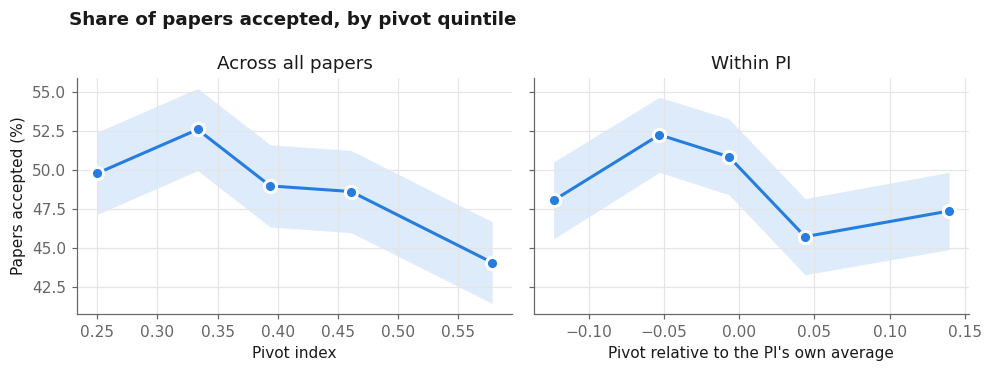

x   mean     se    low   high
              pivot                                   
across papers Q1     0.249  0.498  0.013  0.471  0.524
              Q2     0.333  0.526  0.013  0.500  0.552
              Q3     0.394  0.490  0.013  0.464  0.516
              Q4     0.461  0.486  0.013  0.460  0.513
              Q5     0.578  0.441  0.013  0.415  0.467
within PI     Q1    -0.123  0.481  0.013  0.456  0.505
              Q2    -0.053  0.523  0.012  0.499  0.547
              Q3    -0.007  0.509  0.012  0.484  0.533
              Q4     0.044  0.457  0.012  0.433  0.482
              Q5     0.140  0.474  0.013  0.449  0.499

In [7]:
QUINTILES = ["Q1", "Q2", "Q3", "Q4", "Q5"]


def binned_share(values: pd.Series, outcome: pd.Series) -> pd.DataFrame:
    # Share of papers accepted per quintile of `values`, with a 95% interval
    bins = pd.qcut(values, q=5, labels=QUINTILES)
    grouped = outcome.groupby(bins, observed=True)
    table = pd.DataFrame({"x": values.groupby(bins, observed=True).mean(), "mean": grouped.mean(), "se": grouped.sem()})
    table["low"] = table["mean"] - 1.96 * table["se"]
    table["high"] = table["mean"] + 1.96 * table["se"]
    return table


# Within PI: PIs with at least two decided papers, each paper relative to its PI's average
repeat_pis = decided[decided.groupby("pi_id")["pi_id"].transform("size") > 1].copy()
repeat_pis["pivot_within"] = repeat_pis["pivot"] - repeat_pis.groupby("pi_id")["pivot"].transform("mean")
repeat_pis["accepted_within"] = (
    repeat_pis["accepted"] - repeat_pis.groupby("pi_id")["accepted"].transform("mean") + repeat_pis["accepted"].mean()
)

between = binned_share(decided["pivot"], decided["accepted"])
within = binned_share(repeat_pis["pivot_within"], repeat_pis["accepted_within"])

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
panels = [
    (axs[0], between, "Pivot index", "Across all papers"),
    (axs[1], within, "Pivot relative to the PI's own average", "Within PI"),
]
for ax, table, xlabel, title in panels:
    ax.fill_between(table["x"], table["low"] * 100, table["high"] * 100, color=BLUE, alpha=0.15, linewidth=0)
    ax.plot(table["x"], table["mean"] * 100, "-o", color=BLUE, markersize=8, markeredgecolor="white", markeredgewidth=2)
    ax.set(xlabel=xlabel, title=title)
axs[0].set_ylabel("Papers accepted (%)")
fig.suptitle("Share of papers accepted, by pivot quintile", x=0.06, ha="left", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "pivot_between_within.png", bbox_inches="tight")
plt.show()

pd.concat({"across papers": between, "within PI": within}).round(3)

### 5.2 How much varies within a PI

In [8]:
def variance_split(data: pd.DataFrame, column: str) -> dict:
    within = data[column] - data.groupby("pi_id")[column].transform("mean")
    return {"measure": column, "total SD": data[column].std(), "within-PI SD": within.std(),
            "within share of variance": within.var() / data[column].var()}


pd.DataFrame([variance_split(decided, column) for column in ["pivot", "vendi"]]).set_index("measure").round(3)

,total SD,within-PI SD,within share of variance
measure,,,
pivot,0.118,0.091,0.602
vendi,0.341,0.106,0.096


60% of the pivot's variance is within PI, so a within-PI model has plenty to work with. For Vendi it is only 10%: breadth is mostly a fixed trait of the PI (section 10).

### 5.3 How papers are spread over PIs

In [9]:
volume_groups = pd.cut(decided.groupby("pi_id").size(), [0, 1, 2, 4, 9, np.inf], labels=["1", "2", "3–4", "5–9", "10+"])
volume_table = pd.DataFrame({
    "share of PIs": volume_groups.value_counts(normalize=True, sort=False),
    "share of papers": decided.groupby(decided["pi_id"].map(volume_groups), observed=True).size() / len(decided),
}).rename_axis("decided papers per PI")
volume_table.round(3)

,share of PIs,share of papers
decided papers per PI,,
1,0.306,0.069
2,0.184,0.082
3–4,0.209,0.160
5–9,0.191,0.275
10+,0.111,0.414


About half of the PIs have one or two decided papers, but the 11% of PIs with 10 or more write 41% of the papers. Every model below counts each **paper** once, so prolific PIs weigh more. Section 7 checks what happens when every PI counts once.

## 6. Models, from the simplest up

All models are linear probability models: the outcome is accepted (1) or rejected (0), so a coefficient is a change in acceptance probability. The outcome is always the single paper, never an author's acceptance rate. PI and year enter as dummy variables: one 0/1 column per PI and per year, written `C(pi_id)` and `C(year)`. Standard errors are clustered by PI, because papers by the same PI are not independent.

| Model | Formula | Compares |
|---|---|---|
| M0 | `accepted ~ pivot + C(year)` | papers across all PIs |
| M1 | `accepted ~ pivot + C(pi_id) + C(year)` | each PI's papers with their other papers |
| **M2 (main)** | M1 + `log_n_prior` + `n_authors` | the same, holding history length and team size fixed |
| M3 | `accepted ~ pivot + n_authors + C(pi_year)` | papers by the same PI **in the same year** |

**Why M2 is the main model.** Section 5.1 shows the pooled gap is mostly a difference between PIs, so the PI dummies are needed. History length and team size both change over a PI's career and both relate to acceptance, so M2 holds them fixed. M3 is stricter (same PI, same year, so the same history) but uses only PIs with two or more papers in a year; it serves as a check.

In [10]:
def fit_ols(formula: str, data: pd.DataFrame, weights=None):
    """
    OLS (or weighted OLS) with standard errors clustered by PI.

    use_correction=False: by default statsmodels scales the errors by (N - 1) / (N - K), counting
    every PI dummy in K. The PI dummies sit inside the PI clusters, so they should not count;
    with ~1,500 of them the default would inflate the errors by about 15%.
    """
    model = smf.ols(formula, data) if weights is None else smf.wls(formula, data, weights=weights)
    groups = pd.factorize(data["pi_id"])[0]
    return model.fit(cov_type="cluster", cov_kwds={"groups": groups, "use_correction": False}, use_t=True)


def term_table(fit, terms: list[str]) -> pd.DataFrame:
    # Coefficient, 95% CI and p-value of the listed terms (the PI and year dummies are not shown)
    ci = fit.conf_int()
    return pd.DataFrame({"coefficient": fit.params[terms], "ci_low": ci.loc[terms, 0],
                         "ci_high": ci.loc[terms, 1], "p_value": fit.pvalues[terms]})


def coefficient_table(fits: dict, term: str) -> pd.DataFrame:
    # One row per model: the same term from every model
    table = pd.concat([term_table(fit, [term]).set_axis([name]) for name, fit in fits.items()])
    table["n_papers"] = [int(fit.nobs) for fit in fits.values()]
    return table.rename_axis("model")


ladder = {
    "M0: year dummies": fit_ols("accepted ~ pivot_z + C(year)", decided),
    "M1: + PI dummies": fit_ols("accepted ~ pivot_z + C(pi_id) + C(year)", decided),
    "M2 (main): + controls": fit_ols("accepted ~ pivot_z + log_n_prior + n_authors + C(pi_id) + C(year)", decided),
    "M3: PI×year dummies": fit_ols("accepted ~ pivot_z + n_authors + C(pi_year)", decided),
}

ladder_table = coefficient_table(ladder, "pivot_z")
ladder_table.round(4)

,coefficient,ci_low,ci_high,p_value,n_papers
model,,,,,
M0: year dummies,-0.0215,-0.0345,-0.0086,0.0012,6920
M1: + PI dummies,-0.0119,-0.0278,0.0040,0.1414,6920
M2 (main): + controls,-0.0118,-0.0278,0.0042,0.1494,6920
M3: PI×year dummies,-0.0100,-0.0270,0.0070,0.2475,6920


N is the same in every row. A PI with a single decided paper (or a single paper in a year, in M3) is fit exactly by their own dummy, so that paper says nothing about pivot.

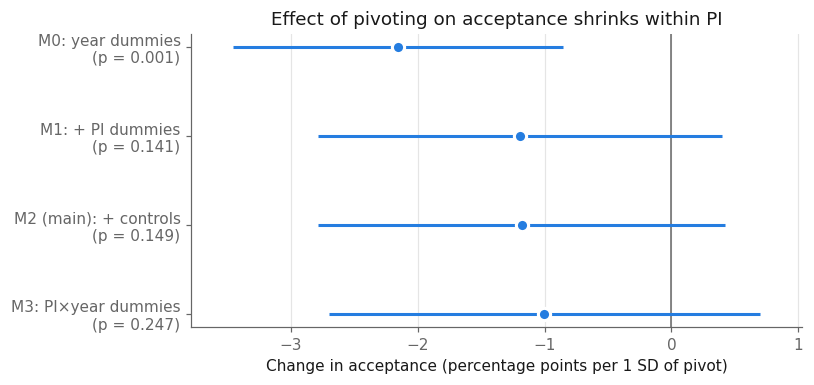

In [11]:
def plot_coefficients(table: pd.DataFrame, title: str, xlabel: str, filename: str, scale: float = 100):
    fig, ax = plt.subplots(figsize=(7.5, 0.6 * len(table) + 1.2))
    positions = np.arange(len(table))[::-1]

    ax.axvline(0, color=MUTED, linewidth=1)
    ax.hlines(positions, table["ci_low"] * scale, table["ci_high"] * scale, color=BLUE, linewidth=2)
    ax.plot(table["coefficient"] * scale, positions, "o", color=BLUE, markersize=8,
            markeredgecolor="white", markeredgewidth=2)

    # the p-value goes into the row label, so it never overlaps the intervals
    row_labels = [f"{name}\n(p = {p_value:.3f})" for name, p_value in zip(table.index, table["p_value"])]
    left = min(table["ci_low"].min() * scale, 0)
    right = max(table["ci_high"].max() * scale, 0)
    ax.set_xlim(left - 0.08 * (right - left), right + 0.08 * (right - left))

    ax.set_yticks(positions, row_labels)
    ax.set(xlabel=xlabel, title=title)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    fig.savefig(FIG_DIR / filename, bbox_inches="tight")
    plt.show()


plot_coefficients(
    ladder_table,
    title="Effect of pivoting on acceptance shrinks within PI",
    xlabel="Change in acceptance (percentage points per 1 SD of pivot)",
    filename="pivot_model_ladder.png",
)

## 7. Checks on the main model (M2)

Each check changes one thing in M2:
- **Drop whole chains:** leave out every resubmitted paper, so the choice of version never depends on the decision.
- **Every PI weighted equally:** each paper gets weight 1 / (its PI's number of papers), so prolific PIs no longer dominate.
- **Pivot quintiles:** dummies in place of a straight line, in case the effect is not linear.
- **Fixed-effects logit:** a conditional logit with PI groups, in place of the linear probability model.

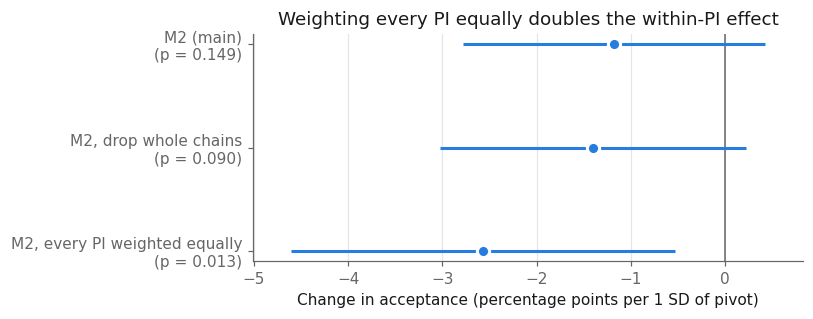

,coefficient,ci_low,ci_high,p_value,n_papers
model,,,,,
M2 (main),-0.0118,-0.0278,0.0042,0.1494,6920
"M2, drop whole chains",-0.0141,-0.0303,0.0022,0.0895,6722
"M2, every PI weighted equally",-0.0257,-0.0461,-0.0053,0.0134,6920


In [12]:
M2_RIGHT = "log_n_prior + n_authors + C(pi_id) + C(year)"    # controls and dummies of M2

robustness = {
    "M2 (main)": ladder["M2 (main): + controls"],
    "M2, drop whole chains": fit_ols(f"accepted ~ pivot_z + {M2_RIGHT}", decided_all_chains),
    "M2, every PI weighted equally": fit_ols(f"accepted ~ pivot_z + {M2_RIGHT}", decided, weights=1 / decided["pi_papers"]),
}
robustness_table = coefficient_table(robustness, "pivot_z")

plot_coefficients(
    robustness_table,
    title="Weighting every PI equally doubles the within-PI effect",
    xlabel="Change in acceptance (percentage points per 1 SD of pivot)",
    filename="pivot_robustness.png",
)
robustness_table.round(4)

In [13]:
decided["pivot_quintile"] = pd.qcut(decided["pivot"], q=5, labels=QUINTILES)
quintile_fit = fit_ols(f"accepted ~ C(pivot_quintile) + {M2_RIGHT}", decided)    # Q1 is the reference
term_table(quintile_fit, [f"C(pivot_quintile)[T.{q}]" for q in QUINTILES[1:]]).round(4)

,coefficient,ci_low,ci_high,p_value
C(pivot_quintile)[T.Q2],0.0232,-0.0202,0.0666,0.2951
C(pivot_quintile)[T.Q3],-0.0062,-0.0513,0.0389,0.7874
C(pivot_quintile)[T.Q4],-0.0133,-0.0612,0.0346,0.5862
C(pivot_quintile)[T.Q5],-0.0304,-0.0792,0.0184,0.2222


In [14]:
# Conditional (fixed-effects) logit: PI effects are conditioned out, year enters as dummies
year_dummies = pd.get_dummies(decided["year"], prefix="year", drop_first=True).astype(float)
logit_X = pd.concat([decided[["pivot_z", "log_n_prior", "n_authors"]], year_dummies], axis=1)

logit_fit = ConditionalLogit(decided["accepted"].to_numpy(), logit_X.to_numpy(), groups=decided["pi_id"].to_numpy()).fit(disp=0)
pivot_position = list(logit_X.columns).index("pivot_z")

print(f"Odds ratio per 1 SD of pivot: {np.exp(logit_fit.params[pivot_position]):.3f}")
print(f"p-value: {logit_fit.pvalues[pivot_position]:.3f}")

C:\Users\marti\anaconda3\Lib\site-packages\statsmodels\discrete\conditional_models.py:80: UserWarning: Dropped 714 groups and 1121 observations for having no within-group variance
  warnings.warn(msg)


Odds ratio per 1 SD of pivot: 0.953
p-value: 0.127


### 7.1 Does the penalty depend on how much a PI publishes?

Equal PI weights make the effect about twice as large. The two numbers answer different questions: the effect for the average *paper* and for the average *PI*. They differ when the penalty depends on how much a PI publishes. This model tests that directly: the pivot effect may change with the log of the PI's number of papers, centred at the median PI (3 papers). A PI's number of papers is constant within PI, so its main effect is absorbed by the PI dummies.

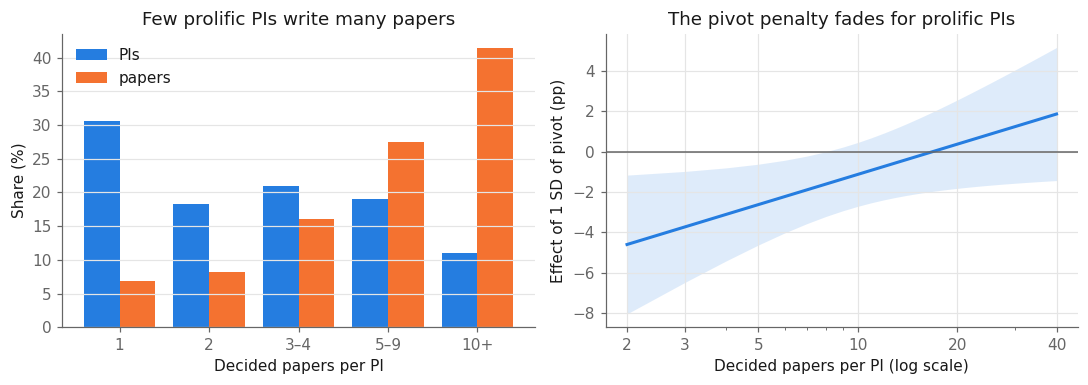

,coefficient,ci_low,ci_high,p_value
pivot_z,-0.0373,-0.0647,-0.0098,0.0079
pivot_z:log_pi_papers,0.0216,0.0017,0.0414,0.0334


In [15]:
median_pi_papers = decided.groupby("pi_id").size().median()
decided["log_pi_papers"] = np.log(decided["pi_papers"] / median_pi_papers)

volume_fit = fit_ols(f"accepted ~ pivot_z + pivot_z:log_pi_papers + {M2_RIGHT}", decided)
volume_terms = ["pivot_z", "pivot_z:log_pi_papers"]

# implied pivot effect for a PI with n decided papers, with a 95% interval
n_grid = np.arange(2, 41)
x = np.log(n_grid / median_pi_papers)
b = volume_fit.params[volume_terms].to_numpy()
V = volume_fit.cov_params().loc[volume_terms, volume_terms].to_numpy()
effect = b[0] + b[1] * x
se = np.sqrt(V[0, 0] + 2 * x * V[0, 1] + x**2 * V[1, 1])

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
positions = np.arange(len(volume_table))
axs[0].bar(positions - 0.2, volume_table["share of PIs"] * 100, width=0.4, color=BLUE, label="PIs")
axs[0].bar(positions + 0.2, volume_table["share of papers"] * 100, width=0.4, color=ORANGE, label="papers")
axs[0].set_xticks(positions, volume_table.index)
axs[0].set(xlabel="Decided papers per PI", ylabel="Share (%)", title="Few prolific PIs write many papers")
axs[0].legend(frameon=False)
axs[0].grid(axis="x", visible=False)

axs[1].fill_between(n_grid, (effect - 1.96 * se) * 100, (effect + 1.96 * se) * 100, color=BLUE, alpha=0.15, linewidth=0)
axs[1].plot(n_grid, effect * 100, color=BLUE)
axs[1].axhline(0, color=MUTED, linewidth=1)
axs[1].set_xscale("log")
axs[1].set_xticks([2, 3, 5, 10, 20, 40], ["2", "3", "5", "10", "20", "40"])
axs[1].set(xlabel="Decided papers per PI (log scale)", ylabel="Effect of 1 SD of pivot (pp)",
           title="The pivot penalty fades for prolific PIs")
plt.tight_layout()
fig.savefig(FIG_DIR / "pivot_by_volume.png", bbox_inches="tight")
plt.show()

term_table(volume_fit, volume_terms).round(4)

## 8. Recency-weighted pivot

The main pivot treats a paper from four years ago like last year's. The recency-weighted pivot halves a past paper's weight every 2 years, so it measures the distance from the PI's *recent* agenda. Same model as M2, with this pivot in place of the main one.

Spearman correlation of the two pivots: 0.99


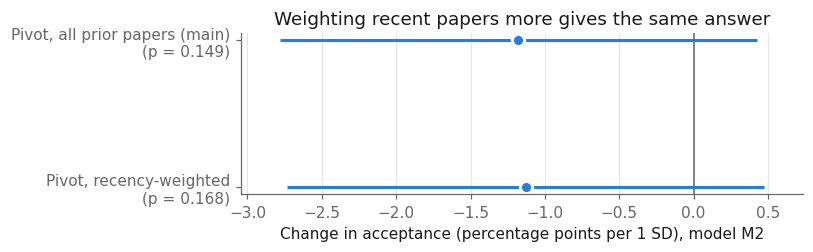

,coefficient,ci_low,ci_high,p_value,n_papers
model,,,,,
"Pivot, all prior papers (main)",-0.0118,-0.0278,0.0042,0.1494,6920
"Pivot, recency-weighted",-0.0113,-0.0273,0.0048,0.1675,6920


In [16]:
recency_fits = {
    "Pivot, all prior papers (main)": ladder["M2 (main): + controls"],
    "Pivot, recency-weighted": fit_ols(f"accepted ~ pivot_recent_z + {M2_RIGHT}", decided),
}
recency_table = pd.concat([
    coefficient_table({name: fit}, term)
    for (name, fit), term in zip(recency_fits.items(), ["pivot_z", "pivot_recent_z"])
])
print(f"Spearman correlation of the two pivots: {decided[['pivot', 'pivot_recent']].corr('spearman').iloc[0, 1]:.2f}")

plot_coefficients(
    recency_table,
    title="Weighting recent papers more gives the same answer",
    xlabel="Change in acceptance (percentage points per 1 SD), model M2",
    filename="pivot_recency.png",
)
recency_table.round(4)

## 9. Reviewer score as the outcome

A binary decision throws away information. The mean reviewer score is finer and also exists for most withdrawn papers. Withdrawals often follow bad reviews, so dropping them hides some of the papers the effect is about.

In [17]:
score_fits = {
    "Score, pooled": fit_ols("mean_score ~ pivot_z + C(year)", scored),
    "Score, PI FE + controls": fit_ols(f"mean_score ~ pivot_z + {M2_RIGHT}", scored),
    "Score, PI×year FE": fit_ols("mean_score ~ pivot_z + n_authors + C(pi_year)", scored),
}
score_table = coefficient_table(score_fits, "pivot_z")
print(f"Standard deviation of the mean score: {scored['mean_score'].std():.2f} points")
score_table.round(4)

Standard deviation of the mean score: 1.21 points


,coefficient,ci_low,ci_high,p_value,n_papers
model,,,,,
"Score, pooled",-0.0841,-0.1115,-0.0566,0.0000,8651
"Score, PI FE + controls",-0.0486,-0.0812,-0.0159,0.0036,8651
"Score, PI×year FE",-0.0456,-0.0806,-0.0106,0.0106,8651


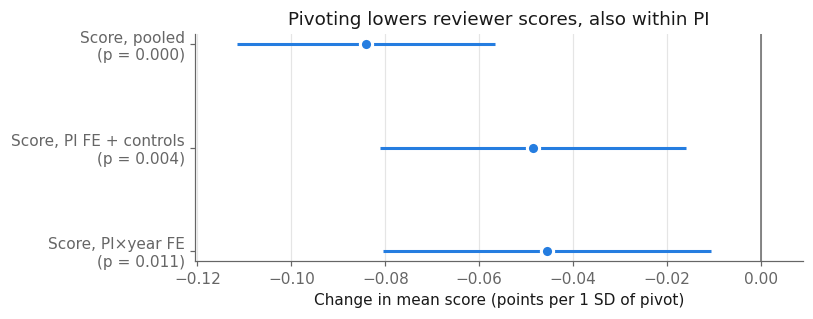

In [18]:
plot_coefficients(
    score_table,
    title="Pivoting lowers reviewer scores, also within PI",
    xlabel="Change in mean score (points per 1 SD of pivot)",
    filename="pivot_score_models.png",
    scale=1,
)

## 10. Vendi score: breadth of the PI's past work

Section 5.2 showed that only 10% of Vendi's variance is within PI. The patterns below show the rest:
- Does a PI's breadth change over their career?
- Do broad PIs (foxes) pivot more?

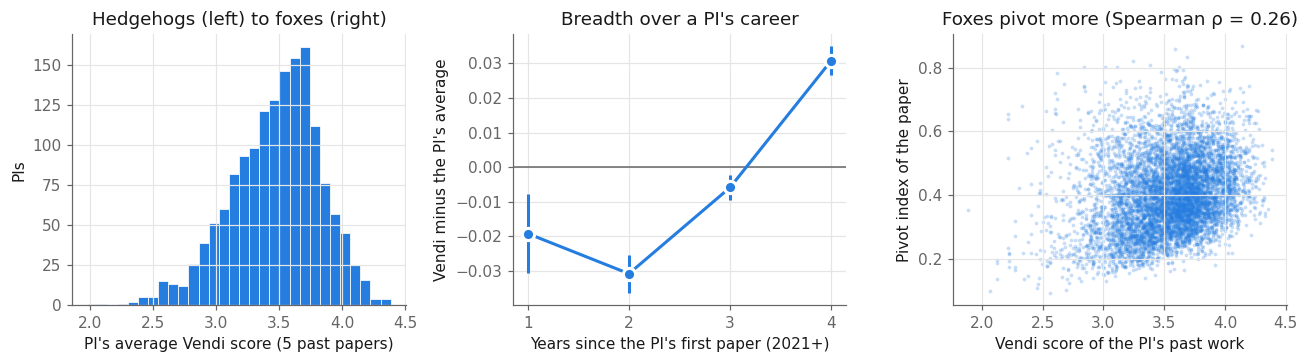

,mean,sem,size
career_years,,,
1,-0.019,0.006,523
2,-0.031,0.003,1589
3,-0.006,0.002,2430
4,0.031,0.002,2378


In [19]:
# One value per PI: their average breadth across their papers
pi_breadth = decided.groupby("pi_id")["vendi"].mean()

# Within PI: breadth relative to the PI's own average, by years since their first paper
decided["vendi_within"] = decided["vendi"] - decided.groupby("pi_id")["vendi"].transform("mean")
by_career = decided.groupby("career_years")["vendi_within"].agg(["mean", "sem", "size"])
by_career = by_career[by_career["size"] >= 50]

fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))

axs[0].hist(pi_breadth, bins=30, color=BLUE, edgecolor="white", linewidth=0.5)
axs[0].set(xlabel="PI's average Vendi score (5 past papers)", ylabel="PIs",
           title="Hedgehogs (left) to foxes (right)")

axs[1].errorbar(by_career.index, by_career["mean"], yerr=1.96 * by_career["sem"], color=BLUE,
                marker="o", markersize=8, markeredgecolor="white", markeredgewidth=2, capsize=0)
axs[1].axhline(0, color=MUTED, linewidth=1)
axs[1].set_xticks(by_career.index)
axs[1].set(xlabel="Years since the PI's first paper (2021+)", ylabel="Vendi minus the PI's average",
           title="Breadth over a PI's career")

axs[2].scatter(decided["vendi"], decided["pivot"], s=6, color=BLUE, alpha=0.25, linewidth=0)
axs[2].set(xlabel="Vendi score of the PI's past work", ylabel="Pivot index of the paper",
           title=f"Foxes pivot more (Spearman ρ = {decided[['vendi', 'pivot']].corr('spearman').iloc[0, 1]:.2f})")

plt.tight_layout()
fig.savefig(FIG_DIR / "vendi_patterns.png", bbox_inches="tight")
plt.show()

by_career.round(3)

**Reading the career panel.** Within a PI, breadth rises with career length. Part of this is mechanical: the 5 papers are drawn from a history that grows and gets older each year, so the pool itself becomes more spread. Breadth computed on a fixed window (for example the last 2 years only) would separate real broadening from this growth.

Models with Vendi, all with PI and year fixed effects and the M2 controls:
- **V1:** Vendi alone.
- **V2:** pivot and Vendi together.
- **V3:** V2 plus their interaction. Is pivoting costlier for hedgehogs (low Vendi) than for foxes?

In [20]:
vendi_fits = {
    "V1 Vendi alone": fit_ols(f"accepted ~ vendi_z + {M2_RIGHT}", decided),
    "V2 pivot + Vendi": fit_ols(f"accepted ~ pivot_z + vendi_z + {M2_RIGHT}", decided),
    "V3 pivot × Vendi": fit_ols(f"accepted ~ pivot_z * vendi_z + {M2_RIGHT}", decided),
}

vendi_terms = ["pivot_z", "vendi_z", "pivot_z:vendi_z"]
pd.concat({name: term_table(fit, [t for t in vendi_terms if t in fit.params]) for name, fit in vendi_fits.items()}).round(4)

coefficient  ci_low  ci_high  p_value
V1 Vendi alone   vendi_z               0.0251 -0.0154   0.0657   0.2244
V2 pivot + Vendi pivot_z              -0.0112 -0.0272   0.0048   0.1699
                 vendi_z               0.0232 -0.0176   0.0639   0.2654
V3 pivot × Vendi pivot_z              -0.0120 -0.0279   0.0040   0.1409
                 vendi_z               0.0244 -0.0164   0.0652   0.2405
                 pivot_z:vendi_z      -0.0079 -0.0217   0.0058   0.2566

In [21]:
vendi_score_fit = fit_ols(f"mean_score ~ pivot_z * vendi_z + {M2_RIGHT}", scored)
term_table(vendi_score_fit, vendi_terms + ["log_n_prior", "n_authors"]).round(4)

,coefficient,ci_low,ci_high,p_value
pivot_z,-0.0490,-0.0815,-0.0165,0.0031
vendi_z,0.0544,-0.0331,0.1420,0.2228
pivot_z:vendi_z,-0.0170,-0.0471,0.0132,0.2707
log_n_prior,0.0438,-0.2086,0.2963,0.7336
n_authors,0.0492,0.0371,0.0614,0.0000


## 11. Out-of-sample check: predicting 2025 decisions

Train on 2022–2024 and test on 2025 papers by PIs seen in training. A logistic regression with one indicator per PI, shrunk towards zero (L2 penalty), plays the role of the PI effect. AUC is the chance that a random accepted paper gets a higher score than a random rejected one (0.5 = guessing).

In [22]:
train = decided[decided["year"] <= 2024]
test = decided[(decided["year"] == 2025) & decided["pi_id"].isin(train["pi_id"])]
train_pis = pd.Categorical(train["pi_id"]).categories


def design_matrix(data: pd.DataFrame, features: list[str], use_pi: bool) -> sparse.csr_matrix:
    blocks = []
    if use_pi:
        pi_codes = pd.Categorical(data["pi_id"], categories=train_pis).codes
        blocks.append(sparse.csr_matrix((np.ones(len(data)), (np.arange(len(data)), pi_codes)),
                                        shape=(len(data), len(train_pis))))
    if features:
        blocks.append(sparse.csr_matrix(data[features].to_numpy(dtype=float)))
    return sparse.hstack(blocks).tocsr()


feature_sets = {
    "pivot only": ([ "pivot_z"], False),
    "PI only": ([], True),
    "PI + pivot": (["pivot_z"], True),
    "PI + Vendi": (["vendi_z"], True),
    "PI + pivot + Vendi": (["pivot_z", "vendi_z"], True),
    "PI + pivot + Vendi + controls": (["pivot_z", "vendi_z", "log_n_prior", "n_authors"], True),
}

auc_rows = []
for name, (features, use_pi) in feature_sets.items():
    model = LogisticRegression(C=0.3, max_iter=3000)
    model.fit(design_matrix(train, features, use_pi), train["accepted"])
    predicted = model.predict_proba(design_matrix(test, features, use_pi))[:, 1]
    auc_rows.append({"features": name, "AUC": roc_auc_score(test["accepted"], predicted)})

auc_table = pd.DataFrame(auc_rows).set_index("features")
print(f"Train: {len(train):,} papers, test: {len(test):,} papers")
auc_table.round(4)

Train: 3,291 papers, test: 2,101 papers


,AUC
features,
pivot only,0.5109
PI only,0.5350
PI + pivot,0.5408
PI + Vendi,0.5340
PI + pivot + Vendi,0.5397
PI + pivot + Vendi + controls,0.5528


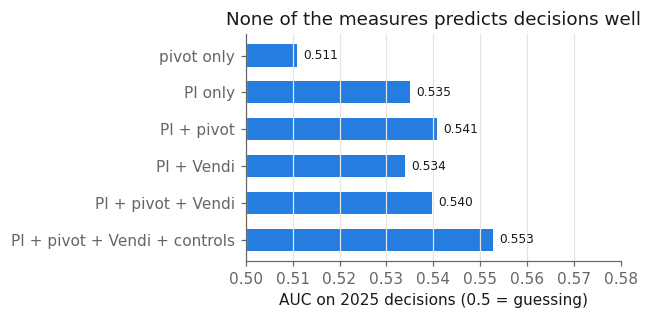

In [23]:
fig, ax = plt.subplots(figsize=(6, 3))
positions = np.arange(len(auc_table))[::-1]
ax.barh(positions, auc_table["AUC"] - 0.5, left=0.5, height=0.6, color=BLUE)
for position, auc in zip(positions, auc_table["AUC"]):
    ax.annotate(f"{auc:.3f}", (auc, position), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=TEXT)
ax.set_yticks(positions, auc_table.index)
ax.set(xlim=(0.5, 0.58), xlabel="AUC on 2025 decisions (0.5 = guessing)",
       title="None of the measures predicts decisions well")
ax.grid(axis="y", visible=False)
plt.tight_layout()
fig.savefig(FIG_DIR / "prediction_auc.png", bbox_inches="tight")
plt.show()

## 12. Summary

The numbers are in the tables above; the reading is:
1. **Across papers**, high-pivot papers are accepted less often (M0: −2.2 points per SD).
2. **Within PI** (M2, the main model), the effect is about half as large (−1.2 points) and not distinguishable from zero. Most of the pooled gap is a difference *between* PIs.
3. **Prolific PIs dominate that average.** With every PI weighted equally the within-PI effect is −2.6 points (p = 0.01). The penalty is about −3.7 points for a PI with 3 papers and fades to zero around 17 papers.
4. **Recency weighting** of the history gives the same answer as the main pivot.
5. **Reviewer scores** fall when a PI pivots, also within PI and within PI-year. The score is the more informative outcome.
6. **Vendi** varies mostly between PIs. Within PI it neither predicts acceptance nor changes how pivoting is received.
7. **Prediction** is weak for every feature set (AUC close to 0.5). These measures describe acceptance; they cannot forecast it.